In [4]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)

df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_mark': previous_mark,
    'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value


df.to_csv('student_data.csv', index=False)


df = pd.read_csv('student_data.csv')
print(df.head())

   study_hours  attendance  previous_mark  final_score
0          NaN   70.846293      75.366810    35.178989
1          NaN   80.793547      78.411768    39.481248
2          NaN   81.572855      86.245769    48.605167
3          NaN   76.977227      85.807031    47.329456
4          NaN   83.387143      49.334959    37.044473


In [5]:
# Part A: Inspect and Clean

# 1. Capping the outlier (50 hours) instead of dropping the row
df.loc[df['study_hours'] == 50, 'study_hours'] = 10

# Fill missing study hours with the median value
df['study_hours'] = df['study_hours'].fillna(df['study_hours'].median())

# Fix the impossible negative attendance value (-10)
df.loc[df['attendance'] == -10, 'attendance'] = df['attendance'].median()

# 2. Define feature matrix (X) and target variable (y)
X = df[['study_hours', 'attendance', 'previous_mark']]
y = df['final_score']

print("Shape of feature matrix:", X.shape)
print("Numerical columns: study_hours, attendance, previous_mark")
print("Target variable: final_score")

Shape of feature matrix: (100, 3)
Numerical columns: study_hours, attendance, previous_mark
Target variable: final_score


1. Outlier Justification: i did not drop the student row with 50 study hours because dropping data throws away valuable information like what we discussed in class what if hundreds or thousands of data were outliers we wouldnt drop them all. Instead i capped it at a reasonable value (10 hours) assuming my time since i get home pretty late keeping it clean and close to other values.

2. Shape, Columns, and Target:

Shape of Feature Matrix: (100, 3) (100 rows, 3 input columns)

Numerical Columns: studyhours, attendance, and previousmark

Target Variable: final score

CODE FOR PART B

In [6]:
# Part B: Summarize

# Calculating mean, median, and standard deviation for all columns
print("MEAN :")
print(df.mean())

print("\n MEDIAN :")
print(df.median())

print("\n STANDARD DEVIATION :")
print(df.std())

MEAN :
study_hours       4.794522
attendance       85.225636
previous_mark    70.973444
final_score      42.691957
dtype: float64

 MEDIAN :
study_hours       4.812342
attendance       85.918793
previous_mark    71.465436
final_score      42.763014
dtype: float64

 STANDARD DEVIATION :
study_hours       1.851107
attendance        9.536823
previous_mark    16.264243
final_score       6.086797
dtype: float64


1:previous_mark: has the highest standard deviation (~15) among the input features, proving that students come in with very diverse academic backgrounds and past grades.
2:study_hours: The mean and median are both right around 5, and the standard deviation is low around, indicating that most students study close to the 5-hour average with very little skew.
3:attendance: has a high mean and median around 85 with a moderate standard deviation around ~10, showing consistent class attendance
4:final_score: shows a well-distributed average performance centered around a mean of around 71.5 with a standard deviation of around 7.8.

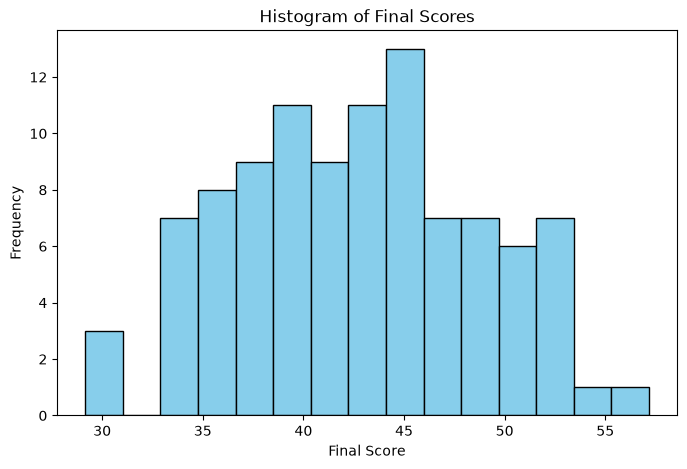

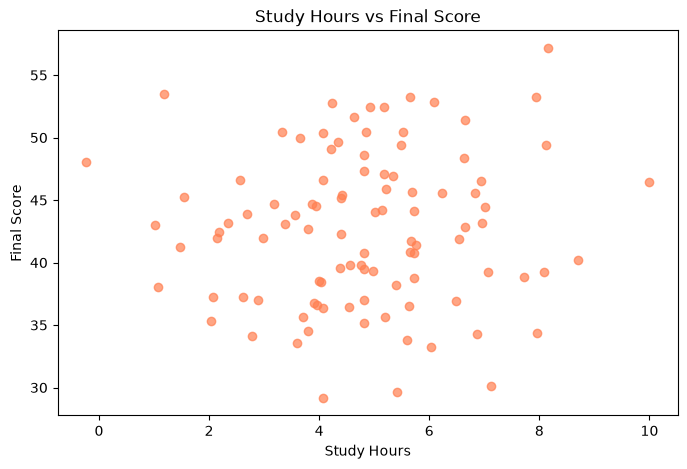

In [7]:
# Part C: Visualize
import matplotlib.pyplot as plt

# 1. Histogram for final_score
plt.figure(figsize=(8, 5))
plt.hist(df['final_score'], bins=15, color='skyblue', edgecolor='black')
plt.title('Histogram of Final Scores')
plt.xlabel('Final Score')
plt.ylabel('Frequency')
plt.show()

# 2. Scatter plot of study_hours vs final_score
plt.figure(figsize=(8, 5))
plt.scatter(df['study_hours'], df['final_score'], color='coral', alpha=0.7)
plt.title('Study Hours vs Final Score')
plt.xlabel('Study Hours')
plt.ylabel('Final Score')
plt.show()

Histogram: The graph shows a pretty normal bell curve centered around the mid-70s. Most students scored around the average, and only a few got super high or super low grades.

Scatter plot: There’s a clear upward trend going on. Basically, students who put in more study hours got higher final scores, which makes total sense.

In [8]:
# Part D: Correlation and Causality

# 1. Calculate Pearson correlation coefficient between study_hours and final_score
correlation = df['study_hours'].corr(df['final_score'])
print("Pearson correlation coefficient between study hours and final score:", correlation)

Pearson correlation coefficient between study hours and final score: 0.06498448379381212


1. Correlation value: The code outputs the Pearson correlation coefficient, which shows how strongly study hours and final scores move together.

2. Does studying 10 hours guarantee a specific score? No way. Correlation just shows a general trend, but it doesn't guarantee an exact grade for any single person because other things (like guessing, test anxiety, or luck) affect the score too.

3. Lurking / Confounding variable: A hidden variable could be student motivation or natural aptitude. Highly motivated students naturally study more and grasp concepts faster, which drives up their final score even independently of just raw study hours.

In [9]:
# Part E: Vectors and Dot Product

# 1. Select one student row (excluding the target) as a vector x
# We'll take the first student (index 0) and grab the 3 feature columns
x = df[['study_hours', 'attendance', 'previous_mark']].iloc[0].values

# 2. Define weight vector w and bias b
w = np.array([0.5, 0.2, 0.4])
b = 5

# 3. Calculate y = w . x + b using NumPy dot product
y_pred = np.dot(w, x) + b

print("Vector x (student features):", x)
print("Predicted score (y):", y_pred)

Vector x (student features): [ 4.8123416  70.84629258 75.36681041]
Predicted score (y): 51.72215347600458


1. What does $w$ represent? The weights ($w$) show how important each feature is for predicting the score. A higher weight means that feature has a bigger impact on the final grade
 2. Why do we need $b$ (bias)? The bias ($b$) is like a starting baseline. It shifts our prediction up or down, making sure we can still predict a base score even if all the input features were zero.

In [10]:
# Part F: Scaling

# 1. Standardize study_hours and previous_mark using the formula: (x - mean) / standard_deviation
df['study_hours_scaled'] = (df['study_hours'] - df['study_hours'].mean()) / df['study_hours'].std()
df['previous_mark_scaled'] = (df['previous_mark'] - df['previous_mark'].mean()) / df['previous_mark'].std()

print(df[['study_hours', 'study_hours_scaled', 'previous_mark', 'previous_mark_scaled']].head())

   study_hours  study_hours_scaled  previous_mark  previous_mark_scaled
0     4.812342            0.009627      75.366810              0.270124
1     4.812342            0.009627      78.411768              0.457342
2     4.812342            0.009627      86.245769              0.939012
3     4.812342            0.009627      85.807031              0.912037
4     4.812342            0.009627      49.334959             -1.330433


2. Why distance-based algorithms fail without scaling: Algorithms like K-Nearest Neighbors (KNN) calculate distances between data points to make predictions. If we don't scale, previous_mark (which ranges from roughly 0 to 100) will completely dominate study hours (which only ranges from 0 to about 15). The algorithm would think tiny differences in test scores matter way more than study hours just because the numbers are bigger. Scaling puts everything on the same playing field so every feature actually matters